# Proyecto integrador — Módulo I
## Evolución de los seguros de Responsabilidad Civil en México (2018–2025)

**Diplomado:** Métodos estadísticos y matemáticos para la ciencia de datos  
**Equipo:** Anna Teresa Piña Cruz, Mariana Alvarado, Zuzuky Diaz Ramos, Ilse Hernández Ramos y Samantha Tavera Flores.

**Objetivo:** Analizar la evolución y concentración de las primas emitidas, la suma asegurada expuesta y los montos de siniestros por tipo de seguro de Responsabilidad Civil en México, utilizando datos públicos de la CNSF.

**Preguntas de investigación**

1. ¿Qué tipos de seguro registraron mayor crecimiento en primas emitidas entre 2018 y 2025 y cuáles tienen mayor participación en 2025?
2. ¿En qué tipos de seguro se concentra la suma asegurada expuesta y cómo cambió su distribución?
3. ¿Qué tipos concentran los mayores montos de siniestros en 2025 y cómo se compara su participación con la de las primas emitidas?

El análisis es descriptivo: buscamos identificar tendencias y diferencias entre segmentos, no determinar causas, rentabilidad ni riesgo actuarial.

In [ ]:
#!mkdir -p /content/data/raw

## 1. Comprensión de los datos

Utilizamos los archivos abiertos de la [Comisión Nacional de Seguros y Fianzas (CNSF)](https://www.cnsf.gob.mx/Transparencia/Paginas/DatosAbiertos.aspx), que reúnen información estadística del mercado asegurador.

| Archivo | Variables principales |
|---|---|
| 33. Emisión | Año, tipo de seguro, moneda, número de incisos, primas emitidas, retenidas y devengadas. |
| 34. Suma asegurada | Año, tipo de seguro, cobertura, suma asegurada y suma asegurada expuesta. |
| 35. Siniestros | Año, tipo de seguro, moneda, número de siniestros, monto de siniestros, monto pagado y recuperaciones. |

Las bases también incluyen variables como entidad, giro y esquema de aseguramiento. Cada fila original es un **registro estadístico agrupado**, no una póliza ni un siniestro individual. En la base final, cada fila representará **un tipo de seguro en un año**.

Los datos permiten responder las preguntas por año y segmento. Las fuentes de emisión y siniestros distinguen categorías de `moneda`; mientras no se confirme que los importes están expresados en una unidad común, los montos agregados y sus porcentajes se presentan únicamente como cálculos preliminares en la escala del CSV. No se ajustan por inflación.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data" / "raw").is_dir():
    ROOT = ROOT.parent

RAW = ROOT / "data" / "raw"
OUT = ROOT / "data" / "processed"
FIG = ROOT / "figures"

if not RAW.is_dir():
    raise FileNotFoundError("Coloca los tres CSV originales en data/raw/.")

OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

In [ ]:
# Cargamos los archivos originales
emision = pd.read_csv(
    RAW / "33 Informacion estadistica del sector asegurador_Responsabilidad Civil_Emision.csv",
    encoding="utf-8-sig"
)
suma = pd.read_csv(
    RAW / "34 Informacion estadistica del sector asegurador_Responsabilidad Civil_Suma Asegurada.csv",
    encoding="utf-8-sig"
)
siniestros = pd.read_csv(
    RAW / "35 Informacion estadistica del sector asegurador_Responsabilidad Civil_Siniestros.csv",
    encoding="utf-8-sig"
)

# Revisamos dimensiones, columnas y periodo de cada archivo
for nombre, tabla in [("Emisión", emision), ("Suma asegurada", suma),
                      ("Siniestros", siniestros)]:
    print(nombre, tabla.shape)
    print("Periodo:", tabla["anio"].min(), "-", tabla["anio"].max())
    tabla.info()
    print("Valores faltantes por columna para la tabla: " + nombre)
    print(tabla.isna().sum())

# Revisamos las categorías de moneda (no implican por sí solas una unidad común)
print("Moneda en emisión:")
display(emision["moneda"].value_counts())
print("Moneda en siniestros:")
display(siniestros["moneda"].value_counts())

Emisión (1028972, 13)
Periodo: 2015 - 2025
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1028972 entries, 0 to 1028971
Data columns (total 13 columns):
 #   Column                 Non-Null Count    Dtype 
---  ------                 --------------    ----- 
 0   anio                   1028972 non-null  int64 
 1   moneda                 1028972 non-null  object
 2   forma_venta            1028972 non-null  object
 3   giro                   1028972 non-null  object
 4   entidad                1028972 non-null  object
 5   tipo_seguro            1028972 non-null  object
 6   subtip_ seguro         1028972 non-null  object
 7   esquema_aseguramiento  1028972 non-null  object
 8   numero_incisos         1028972 non-null  int64 
 9   prima_emitida          1028972 non-null  int64 
 10  prima_retenida         1028972 non-null  int64 
 11  prima_devengada        1028972 non-null  int64 
 12  comision_directa       1028972 non-null  int64 
dtypes: int64(6), object(7)
memory usage: 102.1+ 

,count
moneda,
Nacional,766870
Extranjera,262038
Indizada,64


Moneda en siniestros:


,count
moneda,
Nacional,97096
Extranjera,33177
No disponible,4306
No Disponible,1646


Emisión y siniestros comienzan en 2015, pero suma asegurada en 2018. Por ello, seleccionamos 2018–2025 como periodo compartido.

## 2. Exploración y estadística descriptiva

Primero revisamos la distribución de las variables que responden a las preguntas. Usamos media, mediana, desviación estándar, cuartiles y rango intercuartílico (RIC).

In [ ]:
# Exploración del periodo de interés, sin modificar las bases
variables = [
    (emision, ["prima_emitida", "prima_devengada"]),
    (suma, ["suma_asegurada_expuesta"]),
    (siniestros, ["monto_siniestro"])]

pd.options.display.float_format = "{:,.2f}".format

for tabla, columnas in variables:
    datos_periodo = tabla.loc[tabla["anio"].between(2018, 2025), columnas]
    resumen = datos_periodo.describe()
    resumen.loc["RIC"] = resumen.loc["75%"] - resumen.loc["25%"]
    display(resumen.round(2))

,prima_emitida,prima_devengada
count,"799,062.00","799,062.00"
mean,"161,745.36","150,002.33"
std,"3,632,116.48","12,861,867.70"
min,"-38,783,038.00","-1,680,041.00"
25%,100.00,280.00
50%,"1,869.00","2,016.00"
75%,"14,617.00","13,981.00"
max,"1,593,154,601.00","11,240,210,515.00"
RIC,"14,517.00","13,701.00"


,suma_asegurada_expuesta
count,"1,018,296.00"
mean,"526,755,730.82"
std,"29,664,000,111.80"
min,0.00
25%,"2,178,042.00"
50%,"13,000,000.00"
75%,"69,500,000.00"
max,"15,262,700,000,000.00"
RIC,"67,321,958.00"


,monto_siniestro
count,"102,194.00"
mean,"427,577.68"
std,"8,969,053.61"
min,"-188,261,371.00"
25%,0.00
50%,"4,637.50"
75%,"53,125.25"
max,"1,303,875,296.00"
RIC,"53,125.25"


Es interesante destacar que tenemos valores negativos y máximos muy por encima del percentil al 75%. Estos casos requieren su propio enfoque que veremos más adelante.

2.1 Frecuencias de los tipos de seguro


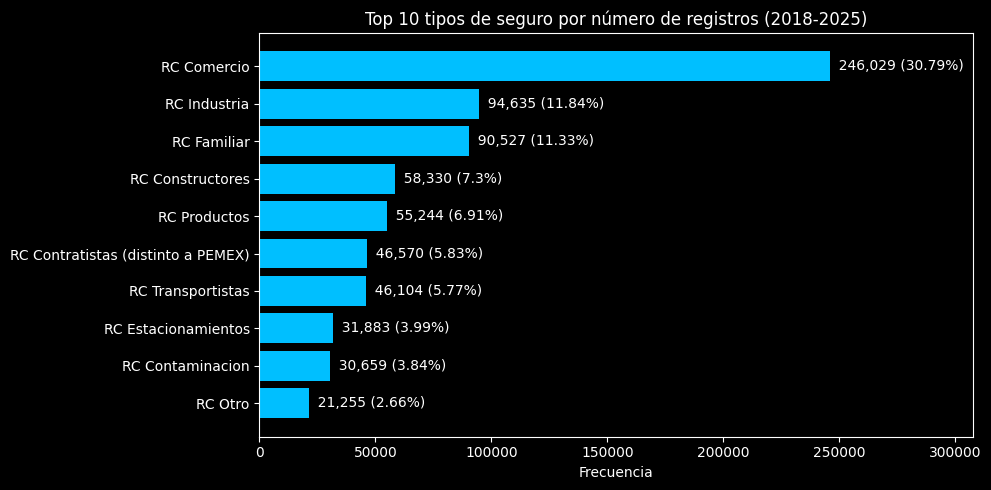

In [ ]:
datos = emision.loc[emision["anio"].between(2018, 2025), "tipo_seguro"]

tabla = pd.DataFrame({
    "frecuencia": datos.value_counts(),
    "porcentaje": (datos.value_counts(normalize=True) * 100).round(2)
}).head(10).sort_values("frecuencia")

fig, ax = plt.subplots(figsize=(10, 5), facecolor="black")
ax.set_facecolor("black")

ax.barh(tabla.index, tabla["frecuencia"], color="deepskyblue")

for i, (f, p) in enumerate(zip(tabla["frecuencia"], tabla["porcentaje"])):
    ax.text(f, i, f"  {f:,} ({p}%)", va="center", color="white")

ax.set_xlabel("Frecuencia", color="white")
ax.set_ylabel("")
ax.set_title("Top 10 tipos de seguro por número de registros (2018-2025)", color="white")
ax.set_xlim(0, tabla["frecuencia"].max() * 1.25)

# Ejes, marcas y bordes en blanco para que se vean sobre el fondo negro
ax.tick_params(colors="white")
for borde in ax.spines.values():
    borde.set_color("white")

plt.tight_layout()
plt.show()

Las frecuencias permiten identificar los tipos de seguro con mayor presencia en los registros analizados. La distribución observada muestra una concentración importante en determinados segmentos, lo que justifica estudiar con mayor detalle su participación en primas, exposición y siniestros.

## 3. Calidad, limpieza y transformación

### 3.1 Diagnóstico de calidad

Revisamos duplicados completos, faltantes y valores negativos con el fin de identificar que los valores con los que estaremos trabajando son coherentes con el análisis y confiables. No eliminamos registros sin evidencia de que sean incorrectos.

In [ ]:
for nombre, tabla in [("Emisión", emision), ("Suma asegurada", suma),
                      ("Siniestros", siniestros)]:
    print(nombre, "- duplicados completos:", tabla.duplicated().sum())
    faltantes = tabla.isna().sum()
    display(faltantes[faltantes > 0])

cols = ["recuperacion_terceros", "recuperacion_reaseguro"]
# Fracción de faltantes por año, expresada en porcentaje.
faltantes_anio = siniestros.groupby("anio")[cols].agg(
    lambda serie: 100 * serie.isna().mean()
)
display(faltantes_anio.round(2))

print("Primas emitidas negativas:", (emision["prima_emitida"] < 0).sum())
print("Montos de siniestros negativos:", (siniestros["monto_siniestro"] < 0).sum())

Emisión - duplicados completos: 0


,0


Suma asegurada - duplicados completos: 0


,0


Siniestros - duplicados completos: 0


,0
recuperacion_terceros,83819
recuperacion_reaseguro,83819


,recuperacion_terceros,recuperacion_reaseguro
anio,,
2015,100.00,100.00
2016,100.00,100.00
2017,100.00,100.00
2018,100.00,100.00
2019,100.00,100.00
2020,100.00,100.00
2021,100.00,100.00
2022,0.00,0.00
2023,0.00,0.00


Primas emitidas negativas: 41550
Montos de siniestros negativos: 33108


**Decisión 1. Conservar faltantes y valores negativos.** En los datos originales, ambas recuperaciones están ausentes hasta 2021 y completas a partir de 2022. Esto sugiere un patrón estructural. No sustituimos los faltantes por cero porque eso afirmaría que no hubo recuperaciones cuando simplemente no se reportaban.

Así evitamos alterar los montos publicados.

In [ ]:
# Examinamos el valor extremo de prima devengada del periodo.
emision_periodo = emision[emision["anio"].between(2018, 2025)]
maximo = emision_periodo.loc[emision_periodo["prima_devengada"].idxmax()]
total_anio = emision_periodo.loc[
    emision_periodo["anio"] == maximo["anio"], "prima_devengada"].sum()

print("Año del máximo:", maximo["anio"])
print("Monto:", maximo["prima_devengada"])
print("Porcentaje del total anual:", round(100 * maximo["prima_devengada"] / total_anio, 2))

# Identificamos los ceros de prima devengada en 2022.
devengada_2022 = emision_periodo.loc[
    emision_periodo["anio"] == 2022, "prima_devengada"
]
print("Porcentaje de ceros en 2022:", round(100 * (devengada_2022 == 0).mean(), 2))

Año del máximo: 2020
Monto: 11240210515
Porcentaje del total anual: 48.68
Porcentaje de ceros en 2022: 34.6


En los resultados originales, un único registro representa el 48.68 % de la prima devengada de 2020; en 2022, el 34.60 % de los registros de esa variable es cero. No utilizamos la prima devengada como denominador de un índice de siniestralidad sin validar su origen.

In [ ]:
def tukey(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); ric = q3 - q1
    return q1 - k * ric, q3 + k * ric

resumen = []
for df, cols in variables:
    for c in cols:
        s = df[c].dropna()
        lo, hi = tukey(s)           # atípicos leves (1.5 x RIC)
        lo3, hi3 = tukey(s, 3)      # atípicos extremos (3 x RIC)

        resumen.append({
            "variable": c,
            "n": len(s),
            "cerca_inferior": lo,
            "cerca_superior": hi,
            "bajo_cerca_inf_%": (s < lo).mean() * 100,
            "sobre_cerca_sup_%": (s > hi).mean() * 100,
            "atipicos_leves_%": ((s < lo) | (s > hi)).mean() * 100,
            "atipicos_extremos_%": ((s < lo3) | (s > hi3)).mean() * 100,
            "n_atipicos": int(((s < lo) | (s > hi)).sum()),
        })

display(pd.DataFrame(resumen).set_index("variable").round(2).T)

variable,prima_emitida,prima_devengada,suma_asegurada_expuesta,monto_siniestro
n,"1,028,972.00","1,028,972.00","1,018,296.00","136,225.00"
cerca_inferior,"-22,273.50","-21,884.00","-98,804,895.00","-85,248.00"
cerca_superior,"37,394.50","37,332.00","170,482,937.00","142,080.00"
bajo_cerca_inf_%,0.33,0.02,0.00,6.54
sobre_cerca_sup_%,16.62,16.17,14.88,16.36
atipicos_leves_%,16.94,16.19,14.88,22.90
atipicos_extremos_%,13.06,12.43,10.76,17.23
n_atipicos,"174,345.00","166,590.00","151,551.00","31,198.00"


Haciendo uso del críterio de IQR determinamos que la prima emitida presenta una distribución desigual: en la exploración del equipo la media supera ampliamente a la mediana. También aparecen montos negativos y extremos. Con este criterio entre el 15 % y el 23 % de los registros quedaban marcados como atípicos.

 Estos resultados describen registros estadísticos, no primas de pólizas individuales; un valor atípico no es necesariamente un error.

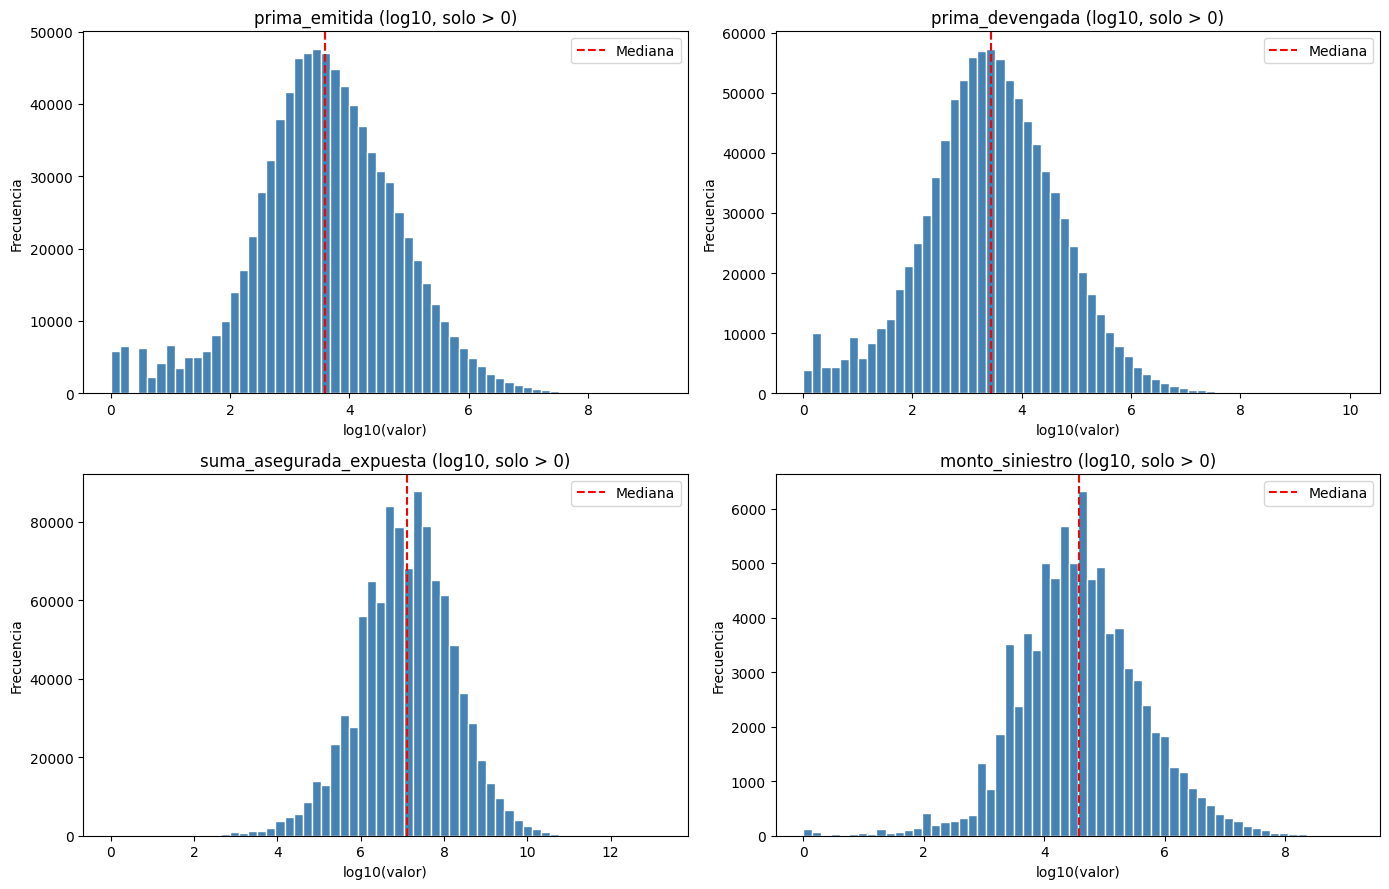

In [ ]:
cols_flat = [(df, c) for df, cols in variables for c in cols]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (df, c) in zip(axes.ravel(), cols_flat):
    s = df[c].dropna()
    pos = s[s > 0]
    ax.hist(np.log10(pos), bins=60, color="steelblue", edgecolor="white")
    ax.axvline(np.log10(pos.median()), color="red", ls="--", label="Mediana")
    ax.set(title=f"{c} (log10, solo > 0)", xlabel="log10(valor)", ylabel="Frecuencia")
    ax.legend()

plt.tight_layout(); plt.show()

Las cuatro variables tienen forma de campana en escala log, es decir, son aproximadamente log-normales. Los valores grandes que el críterio IQR marcaba como atípicos son la cola natural de esa distribución, no errores en bloque.

/tmp/ipykernel_2911/1340402591.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(datos_log, labels=[c for _, c in cols_flat], vert=False, showfliers=True,


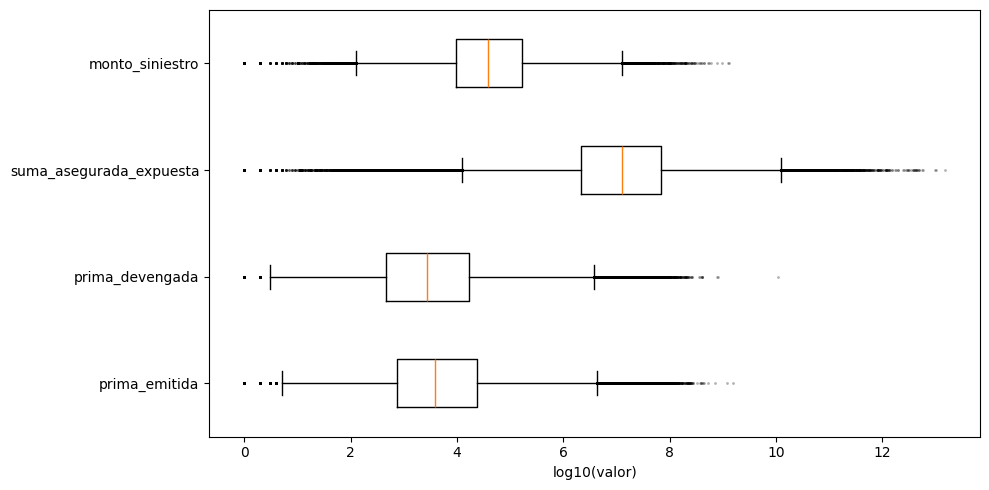

In [ ]:
datos_log = [np.log10(df.loc[df[c] > 0, c]) for df, c in cols_flat]

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(datos_log, labels=[c for _, c in cols_flat], vert=False, showfliers=True,
           flierprops=dict(marker=".", markersize=2, alpha=0.3))
ax.set_xlabel("log10(valor)")
plt.tight_layout(); plt.show()

En log, la caja es razonable y los bigotes cubren casi todo el rango: los atípicos que quedan son una pequeña fracción.

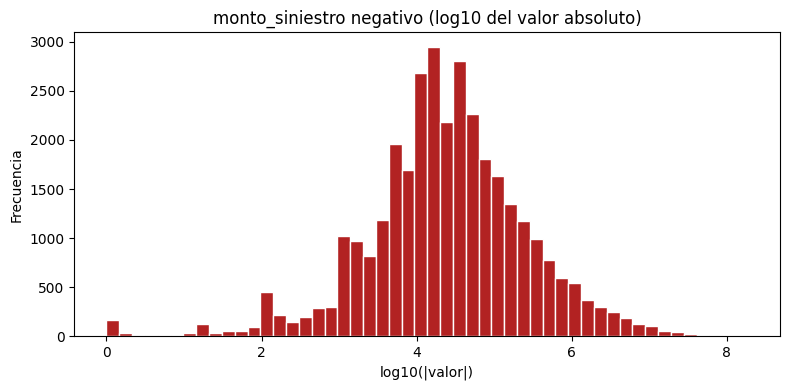

In [ ]:
neg = siniestros.loc[siniestros["monto_siniestro"] < 0, "monto_siniestro"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(np.log10(-neg), bins=50, color="firebrick", edgecolor="white")
ax.set(title="monto_siniestro negativo (log10 del valor absoluto)",
       xlabel="log10(|valor|)", ylabel="Frecuencia")
plt.tight_layout(); plt.show()

Los negativos también tienen forma de campana log-normal, centrada en log ≈ 4.3, muy parecida a la de los positivos (log ≈ 4.6).
Eso es una señal fuerte de que no son errores aleatorios: parecen reversas, cancelaciones o ajustes de siniestros reales, con magnitudes similares a los siniestros normales.

In [ ]:
# Candidatos a revisar
display(emision.nlargest(5, "prima_devengada"))
display(suma.nlargest(5, "suma_asegurada_expuesta"))
print("Primas simbólicas (0 a 10):", emision["prima_emitida"].between(0, 10).sum())
print("Siniestros simbólicos (0 a 10):", siniestros["monto_siniestro"].between(1, 10).sum())

,anio,moneda,forma_venta,giro,entidad,tipo_seguro,subtip_ seguro,esquema_aseguramiento,numero_incisos,prima_emitida,prima_retenida,prima_devengada,comision_directa
463394,2020,Nacional,Agentes Persona Moral,Casa Habitaciòn,Aguascalientes,RC Familiar,Otro,Ocurrence,283153,9301014,3249594,11240210515,5862
996416,2025,Nacional,Fuerza de Venta Interna o Casa Matriz,Administracion publica en general,Queretaro,RC Riesgos Gubernamentales,Negocio gubernamental,Ocurrence,55,1217831161,278760909,829879464,0
808073,2023,Extranjera,Agentes Persona Moral,"Comercio al por menor de combustibles, aceites...",Ciudad de Mexico,RC Comercio,Otro,Ocurrence,59,380207726,2385210,796885607,351605
914354,2024,Extranjera,Fuerza de Venta Interna o Casa Matriz,Oficinas publicas,Ciudad de Mexico,RC Industria,Negocio gubernamental,Ocurrence,2,425090625,0,413672524,0
907418,2024,Extranjera,Agentes Persona Moral,"Comercio al por menor de combustibles, aceites...",Ciudad de Mexico,RC Comercio,Otro,Ocurrence,56,438434634,1638906,409943322,314882


,anio,giro,entidad,esquema_aseguramietno,tipo_seguro,subtipo_seguro,cobertura,numero_incisos,suma_asegurada,suma_asegurada_expuesta
173087,2019,Fabricacion de productos farmaceuticos,MEXICO,Ocurrence,RC Aviones,Otro,Aviacion,110,"30,690,000,000,000.00","15,262,700,000,000.00"
994176,2025,Casa Habitaciòn,Ciudad de Mexico,Ocurrence,RC Aviones,Otro,Aviacion,1406,"10,429,200,000,000.00","10,389,400,000,000.00"
788683,2024,Casa Habitaciòn,Ciudad de Mexico,Ocurrence,RC Aviones,Otro,Aviacion,1245,"10,053,700,000,000.00","10,012,900,000,000.00"
596927,2022,Transporte maritimo,Ciudad de Mexico,Ocurrence,RC Barcos,Otro,Buques,805,"6,299,550,000,000.00","5,765,530,000,000.00"
596345,2022,Servicios relacionados con el transporte aereo,Nuevo Leon,Ocurrence,RC Aviones,Otro,Aviacion,1417,"5,670,920,000,000.00","5,653,300,000,000.00"


Primas simbólicas (0 a 10): 174743
Siniestros simbólicos (0 a 10): 298


Dados los valores extremos que observamos en el box plot analizamos a detalle los registros que se encuentran en las colas más pesadas.

La fila de 2020 es la única claramente incoherente: con 283,153 incisos, 9.3 M de prima emitida da ~33 por inciso, mientras que la devengada con un total de 11,240,210,515 daría ~39,700.

### Suma Asegurada

Los extremos son RC Aviones y RC Barcos (coberturas Aviación y Buques). Es coherente con límites enormes de esos riesgos.

In [ ]:
#############################################################################################
# Elimina la fila sospechosa (2020, RC Familiar, Aguascalientes, devengada ≈ 11,240 M)
mask = (
    emision["anio"].eq(2020)
    & emision["numero_incisos"].eq(283153)
    & emision["prima_devengada"].eq(11240210515)
)

print("Filas a eliminar:", mask.sum())

emision_limpia = emision.loc[~mask].copy()

print(f"Antes: {len(emision):,} | Después: {len(emision_limpia):,}")
#############################################################################################

'mask = (\n    emision["anio"].eq(2020)\n    & emision["numero_incisos"].eq(283153)\n    & emision["prima_devengada"].eq(11240210515)\n)\n\nprint("Filas a eliminar:", mask.sum())\n\nemision_limpia = emision.loc[~mask].copy()\n\nprint(f"Antes: {len(emision):,} | Después: {len(emision_limpia):,}")\n'

### 3.2 Homologar tipos de seguro

**Decisión 2.** Los nombres de los tipos de seguro presentan abreviaturas y diferencias de escritura. Usamos un diccionario de equivalencias para evitar que se contabilicen como categorías distintas. Conservamos `tipo_seguro` y creamos `tipo_homologado`. No modificamos las entidades, porque no son parte de las preguntas de investigación.

In [ ]:
equivalencias = {
    'Responsabilidad Civil Aviones': 'RC Aviones',
    'Responsabilidad Civil Barcos': 'RC Barcos',
    'Responsabilidad Civil Carreteras': 'RC Carreteras',
    'Responsabilidad Civil Comercio': 'RC Comercio',
    'Responsabilidad Civil Constructores': 'RC Constructores',
    'Responsabilidad Civil Contaminacion': 'RC Contaminacion',
    'Responsabilidad Civil Contratistas (distinto a PEMEX)': 'RC Contratistas (distinto a PEMEX)',
    'Responsabilidad Civil Contratistas distinto PEMEX': 'RC Contratistas (distinto a PEMEX)',
    'Responsabilidad Civil Ensayos Clinicos': 'RC Ensayos clinicos',
    'Responsabilidad Civil Ensayos clinicos': 'RC Ensayos clinicos',
    'Responsabilidad Civil Estacionamientos': 'RC Estacionamientos',
    'Responsabilidad Civil Eventos': 'RC Eventos',
    'Responsabilidad Civil Familiar': 'RC Familiar',
    'Responsabilidad Civil Gaseras': 'RC Gaseras',
    'Responsabilidad Civil Guarderias, Escolar o Colegios': 'RC Guarderias, Escolar o Colegios',
    'Responsabilidad Civil Guarderias, Escolar, Colegi': 'RC Guarderias, Escolar o Colegios',
    'Responsabilidad Civil Hoteles': 'RC Hoteles',
    'Responsabilidad Civil Industria': 'RC Industria',
    'Responsabilidad Civil Otro': 'RC Otro',
    'Responsabilidad Civil Otros': 'RC Otro',
    'Responsabilidad Civil PEMEX': 'RC PEMEX',
    'Responsabilidad Civil Productos': 'RC Productos',
    'Responsabilidad Civil Riesgos Profesionales': 'RC Riesgos Profesionales',
    'Responsabilidad Civil Talleres': 'RC Talleres',
    'Responsabilidad Civil Transportistas': 'RC Transportistas',
    'Responsabilidad Civil Viajero': 'RC Viajero',
    'RC Ensayos Clinicos': 'RC Ensayos clinicos',
}

# Aplicamos las equivalencias a las tres bases.
for nombre, tabla in [("Emisión", emision), ("Suma asegurada", suma),
                      ("Siniestros", siniestros)]:
    tabla["tipo_homologado"] = tabla["tipo_seguro"].replace(equivalencias)
    print(nombre, tabla["tipo_seguro"].nunique(), "→",
          tabla["tipo_homologado"].nunique())

# Usamos los tipos de suma asegurada como referencia.
catalogo = suma["tipo_homologado"].unique()
assert emision["tipo_homologado"].isin(catalogo).all()
assert siniestros["tipo_homologado"].isin(catalogo).all()

Emisión 46 → 24
Suma asegurada 24 → 24
Siniestros 50 → 24


La homologación reduce las categorías de emisión de 46 a 24 y las de siniestros de 50 a 24, según los resultados originales. Las equivalencias deben revisarse si se actualizan los archivos.

### 3.3 Seleccionar el periodo y agrupar las bases

**Decisión 3.** Filtramos las tres fuentes a 2018–2025 y agrupamos antes de unir. Las bases originales tienen distintas dimensiones (por ejemplo, cobertura y causa del siniestro); unirlas directamente por año y tipo podría multiplicar los montos. Al agrupar, perdemos ese detalle, pero obtenemos la unidad de observación requerida.

In [ ]:
llaves = ["anio", "tipo_homologado"]

emision_rc = emision[emision["anio"].between(2018, 2025)]
suma_rc = suma[suma["anio"].between(2018, 2025)]
siniestros_rc = siniestros[siniestros["anio"].between(2018, 2025)]

cols_emision = ["prima_emitida", "prima_retenida", "prima_devengada"]
cols_suma = ["suma_asegurada_expuesta"]
cols_siniestros = ["monto_siniestro", "monto_pagado", "recuperacion_reaseguro"]

# min_count=1 conserva NaN si todos los valores del grupo están ausentes.
emision_agg = emision_rc.groupby(llaves)[cols_emision].sum(min_count=1).reset_index()
suma_agg = suma_rc.groupby(llaves)[cols_suma].sum(min_count=1).reset_index()
siniestros_agg = siniestros_rc.groupby(llaves)[cols_siniestros].sum(min_count=1).reset_index()

# Validamos llaves únicas y comprobamos que los montos no cambien.
for original, agrupada, columnas in [
    (emision_rc, emision_agg, cols_emision),
    (suma_rc, suma_agg, cols_suma),
    (siniestros_rc, siniestros_agg, cols_siniestros)
]:
    assert not agrupada.duplicated(llaves).any()
    for columna in columnas:
        assert np.isclose(original[columna].sum(min_count=1),
                          agrupada[columna].sum(min_count=1), rtol=1e-12, atol=1, equal_nan=True)
    print(len(original), "registros →", len(agrupada), "filas agrupadas")

799062 registros → 179 filas agrupadas
1018296 registros → 179 filas agrupadas
102194 registros → 168 filas agrupadas


In [ ]:
# Integramos por año y tipo; preservamos todas las combinaciones.
df_final = emision_agg.merge(
    suma_agg, on=llaves, how="outer", validate="one_to_one", indicator="union_suma"
)
df_final = df_final.merge(
    siniestros_agg, on=llaves, how="outer", validate="one_to_one",
    indicator="union_siniestros"
)

display(df_final["union_suma"].value_counts())
display(df_final["union_siniestros"].value_counts())
display(df_final.loc[df_final["union_siniestros"] == "left_only", llaves])

assert not df_final.duplicated(llaves).any()
for agrupada, columnas in [(emision_agg, cols_emision), (suma_agg, cols_suma),
                           (siniestros_agg, cols_siniestros)]:
    for columna in columnas:
        assert np.isclose(df_final[columna].sum(min_count=1),
                          agrupada[columna].sum(min_count=1), rtol=1e-12, atol=1, equal_nan=True)

df_final.to_csv(OUT / "base_integrada.csv", index=False)

,count
union_suma,
both,179
left_only,0
right_only,0


,count
union_siniestros,
both,168
left_only,11
right_only,0


,anio,tipo_homologado
16,2018,RC PEMEX
33,2019,RC Gaseras
55,2020,RC Gaseras
77,2021,RC Gaseras
82,2021,RC PEMEX
99,2022,RC Gaseras
126,2023,RC PEMEX
143,2024,RC Gaseras
148,2024,RC PEMEX
150,2024,RC Riesgos Ciberneticos


**Decisión 4. Conservar combinaciones sin coincidencia.** Utilizamos `outer` para no perder grupos de ninguna fuente y `validate="one_to_one"` para comprobar la cardinalidad. En los resultados originales se identificaron 179 pares año/tipo en emisión y suma asegurada, y 168 en siniestros; 11 pares no tenían siniestros reportados en la base. Esto no significa que hayan tenido cero siniestros.

## 4. Visualización de datos

Los montos que aparecen en esta sección son sumas de los valores publicados, **preliminares hasta verificar su unidad monetaria común**. Los porcentajes se calculan con el total de cada fuente y periodo, no únicamente con las categorías mostradas.

**4.1 Correlaciones entre variables**

Además de estudiar la evolución temporal y la participación de los distintos
tipos de seguro, analizamos la asociación lineal entre las principales
variables numéricas de la base integrada.

La correlación permite identificar variables que afectan directamente el comportamiento de otra; sin embargo, una correlación elevada no implica causalidad.

,prima_emitida,prima_retenida,prima_devengada,suma_asegurada_expuesta,monto_siniestro,monto_pagado
prima_emitida,1.00,0.96,0.74,0.50,0.65,0.75
prima_retenida,0.96,1.00,0.72,0.39,0.57,0.69
prima_devengada,0.74,0.72,1.00,0.39,0.45,0.48
suma_asegurada_expuesta,0.50,0.39,0.39,1.00,0.18,0.26
monto_siniestro,0.65,0.57,0.45,0.18,1.00,0.91
monto_pagado,0.75,0.69,0.48,0.26,0.91,1.00



Correlaciones con monto_siniestro:


,monto_siniestro
monto_siniestro,1.00
monto_pagado,0.91
prima_emitida,0.65
prima_retenida,0.57
prima_devengada,0.45
suma_asegurada_expuesta,0.18


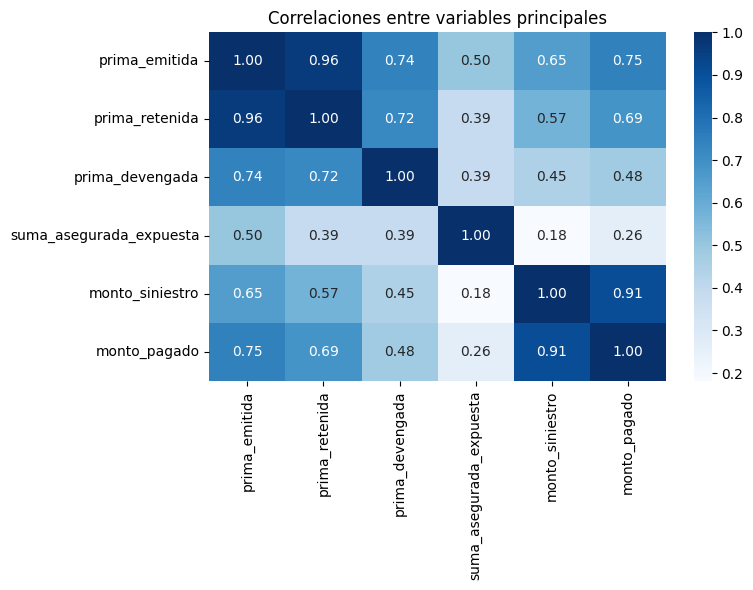

In [ ]:
import seaborn as sns

variables_corr = [
    "prima_emitida",
    "prima_retenida",
    "prima_devengada",
    "suma_asegurada_expuesta",
    "monto_siniestro",
    "monto_pagado"
]

corr = (
    df_final[variables_corr]
    .corr()
)

display(corr.round(2))

print("\nCorrelaciones con monto_siniestro:")

display(
    corr["monto_siniestro"]
    .sort_values(ascending=False)
    .round(2)
)

plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap="Blues",
    fmt=".2f"
)

plt.title("Correlaciones entre variables principales")

plt.tight_layout()

plt.savefig(
    FIG / "00_correlaciones.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

**Interpretación.**

La matriz de correlaciones permite identificar asociaciones lineales entre las
variables incluidas en la base integrada.

Se espera observar correlaciones positivas entre prima_emitida,
prima_retenida y prima_devengada, ya que representan distintas medidas del
volumen de negocio.

Asimismo, una asociación positiva entre las primas, las sumas aseguradas y
los montos de siniestros sugeriría que los segmentos con mayor actividad
aseguradora también concentran mayores niveles de exposición y mayores montos
agregados de siniestros.

Estas asociaciones son descriptivas y no deben interpretarse como relaciones
causales.

**4.2 Evolución de las tres variables principales**

,prima_emitida,suma_asegurada_expuesta,monto_siniestro
anio,,,
2018,11.46,"38,688.83",3.05
2019,13.48,"83,263.58",2.98
2020,12.72,"56,601.90",4.52
2021,17.42,"65,639.41",4.18
2022,15.40,"69,238.83",7.08
2023,17.36,"58,405.90",5.11
2024,19.54,"80,672.94",6.81
2025,21.88,"83,881.86",9.97


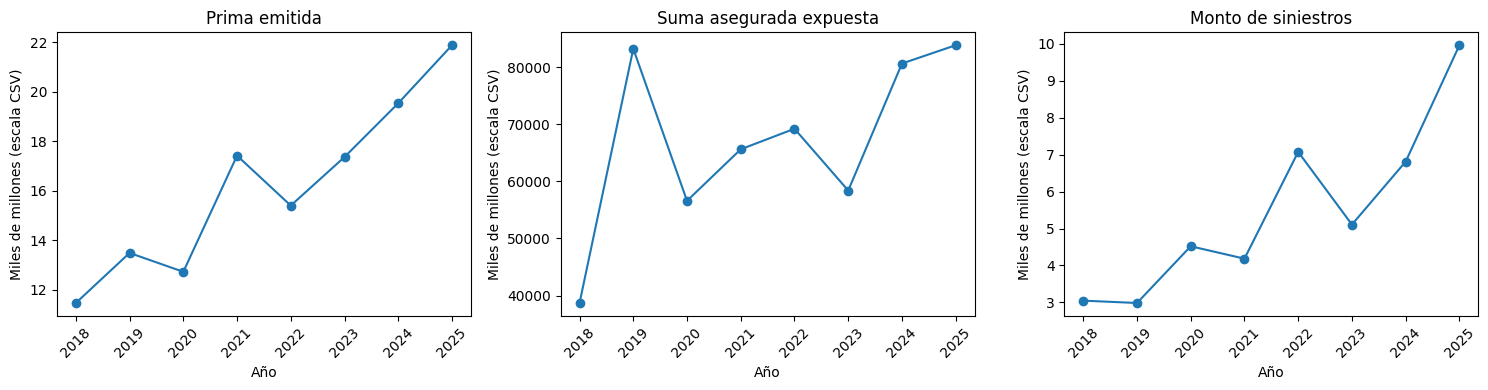

In [ ]:
# Evolución de las tres variables principales.
columnas = ["prima_emitida", "suma_asegurada_expuesta", "monto_siniestro"]
anual = df_final.groupby("anio")[columnas].sum(min_count=1)
display((anual / 1e9).round(2))
anual.to_csv(OUT / "resumen_anual.csv")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, columna, titulo in zip(
    axes, columnas, ["Prima emitida", "Suma asegurada expuesta", "Monto de siniestros"]
):
    ax.plot(anual.index, anual[columna] / 1e9, marker="o")
    ax.set_title(titulo)
    ax.set_xlabel("Año")
    ax.set_ylabel("Miles de millones (escala CSV)")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(FIG / "01_evolucion.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación.**

Entre 2018 y 2025, las primas emitidas y los montos de siniestros aumentaron aproximadamente 91 % y 227 %, respectivamente, en los cálculos originales. La suma asegurada expuesta presenta oscilaciones. No implica crecimiento real (no se ajustó por inflación), ni permite inferir la causa del cambio.

**4.3 Crecimiento y concentración de primas emitidas**

Comparamos el crecimiento porcentual de los tipos presentes en ambos años y su participación en el total anual. Separamos los tipos sin dato inicial o con base inicial no positiva, pues no es posible calcular de la misma forma su crecimiento.

Cinco tipos de mayor crecimiento relativo:


,prima_2018,prima_2025,participacion_2018_pct,participacion_2025_pct,crecimiento_pct
tipo_homologado,,,,,
RC Gaseras,"1,305,591.00","21,512,231.00",0.01,0.10,"1,547.70"
RC Otro,"43,777,237.00","427,460,737.00",0.38,1.95,876.45
RC Eventos,"15,002,724.00","101,242,156.00",0.13,0.46,574.83
RC Transportistas,"31,534,535.00","159,677,300.00",0.28,0.73,406.36
RC Productos,"158,347,153.00","559,176,705.00",1.38,2.56,253.13


Líderes por crecimiento: RC Gaseras, RC Otro, RC Eventos, RC Transportistas, RC Productos
Cinco tipos con mayor prima en 2025:


,prima_2018,prima_2025,participacion_2018_pct,participacion_2025_pct,crecimiento_pct
tipo_homologado,,,,,
RC Comercio,"2,913,229,398.00","8,128,850,189.00",25.43,37.15,179.03
RC Industria,"2,458,044,711.00","2,776,701,337.00",21.46,12.69,12.96
RC Riesgos Profesionales,"2,016,263,165.00","2,598,368,816.00",17.60,11.88,28.87
RC Riesgos Gubernamentales,NaN,"1,217,393,596.00",NaN,5.56,NaN
RC Aviones,"767,751,090.00","975,144,291.00",6.70,4.46,27.01


Tipos sin crecimiento comparable:


,prima_2018,prima_2025,participacion_2018_pct,participacion_2025_pct,crecimiento_pct
tipo_homologado,,,,,
RC Riesgos Ciberneticos,NaN,"138,005,937.00",NaN,0.63,NaN
RC Riesgos Gubernamentales,NaN,"1,217,393,596.00",NaN,5.56,NaN


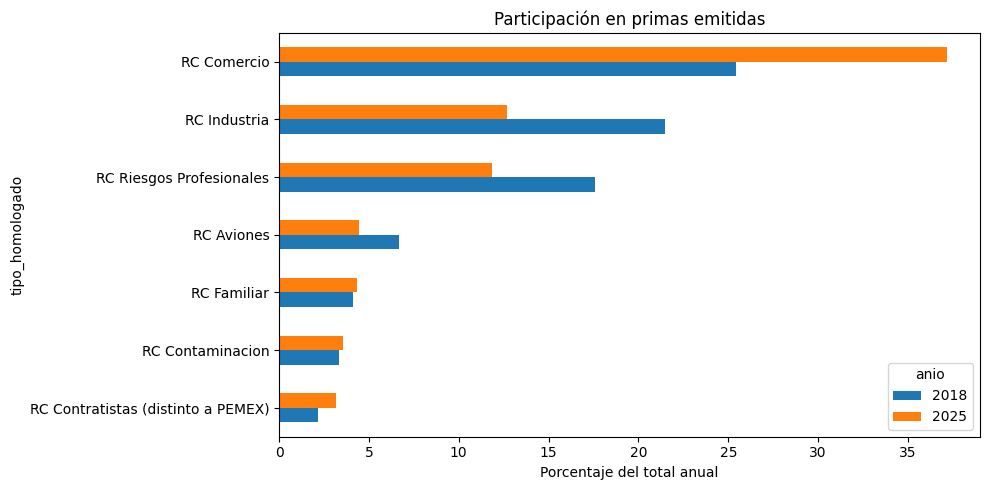

In [ ]:
# Participación anual: prima del tipo / prima total del año.
primas = df_final.pivot(index="tipo_homologado", columns="anio", values="prima_emitida")
primas = primas[[2018, 2025]]
participacion_primas = 100 * primas / primas.sum()

crecimiento = primas[2025].sub(primas[2018]).div(primas[2018]) * 100
crecimiento = crecimiento.where((primas[2018] > 0) & primas[2025].notna())

resumen_primas = pd.DataFrame({
    "prima_2018": primas[2018],
    "prima_2025": primas[2025],
    "participacion_2018_pct": participacion_primas[2018],
    "participacion_2025_pct": participacion_primas[2025],
    "crecimiento_pct": crecimiento
})

print("Cinco tipos de mayor crecimiento relativo:")
mayor_crecimiento = resumen_primas.dropna(subset=["crecimiento_pct"]).sort_values(
    "crecimiento_pct", ascending=False).head(5)
display(mayor_crecimiento.round(2))
print("Líderes por crecimiento:", ", ".join(mayor_crecimiento.index))

print("Cinco tipos con mayor prima en 2025:")
display(resumen_primas.sort_values("prima_2025", ascending=False).head(5).round(2))

print("Tipos sin crecimiento comparable:")
display(resumen_primas.loc[resumen_primas["crecimiento_pct"].isna()].round(2))

resumen_primas.to_csv(OUT / "crecimiento_primas.csv")

# Para las barras agrupadas seleccionamos tipos presentes en ambos años.
vista = participacion_primas.dropna().sort_values(2025).tail(7)
ax = vista.plot.barh(figsize=(10, 5), title="Participación en primas emitidas")
ax.set_xlabel("Porcentaje del total anual")
plt.tight_layout()
plt.savefig(FIG / "02_participacion_primas.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación.**

RC Comercio pasó de 25.4 % a 37.2 % de las primas emitidas, mientras RC Industria pasó de 21.5 % a 12.7 %. Comercio aumentó alrededor de 179 % en monto. Un crecimiento porcentual alto puede partir de una base pequeña y no equivale necesariamente a una gran participación. Los tipos sin dato comparable en 2018 se muestran en la tabla de 2025, no se tratan como ceros.

In [ ]:
# Estadística descriptiva por tipo de seguro en 2025.
p2025 = primas[2025].dropna()
estadisticos = p2025.describe()
estadisticos["RIC"] = p2025.quantile(0.75) - p2025.quantile(0.25)
display((estadisticos.drop("count") / 1e6).round(2))
print("Tipos con datos:", len(p2025))

# Percentiles adicionales

p90 = p2025.quantile(0.90)

p95 = p2025.quantile(0.95)

print("Percentil 90:", round(p90/1e6, 2), "millones")

print("Percentil 95:", round(p95/1e6, 2), "millones")

,2025
mean,911.69
std,"1,701.67"
min,1.55
25%,128.81
50%,354.77
75%,826.36
max,"8,128.85"
RIC,697.55


Tipos con datos: 24
Percentil 90: 2184.08 millones
Percentil 95: 2749.95 millones


En 2025 la media por tipo fue de aproximadamente 911.7 millones y la mediana de 354.8 millones (escala del CSV). La diferencia refleja la concentración de los montos en algunos segmentos.

Los percentiles complementan este análisis.
El percentil 90 representa el valor por debajo
del cual se encuentra el 90 % de los tipos de
seguro, mientras que el percentil 95 representa
el valor por debajo del cual se encuentra el
95 % de los tipos analizados.

La diferencia entre la media, la mediana y los
percentiles altos refuerza la existencia de una
distribución asimétrica y concentrada en unos
cuantos segmentos.

**4.4 Concentración de la suma asegurada expuesta**

anio,participacion_2018_pct,participacion_2025_pct,cambio_pp
tipo_homologado,,,
RC Aviones,16.53,30.12,13.59
RC Comercio,12.11,17.10,4.99
RC Barcos,24.99,12.64,-12.35
RC Familiar,10.61,10.00,-0.61
RC Industria,7.92,4.96,-2.96


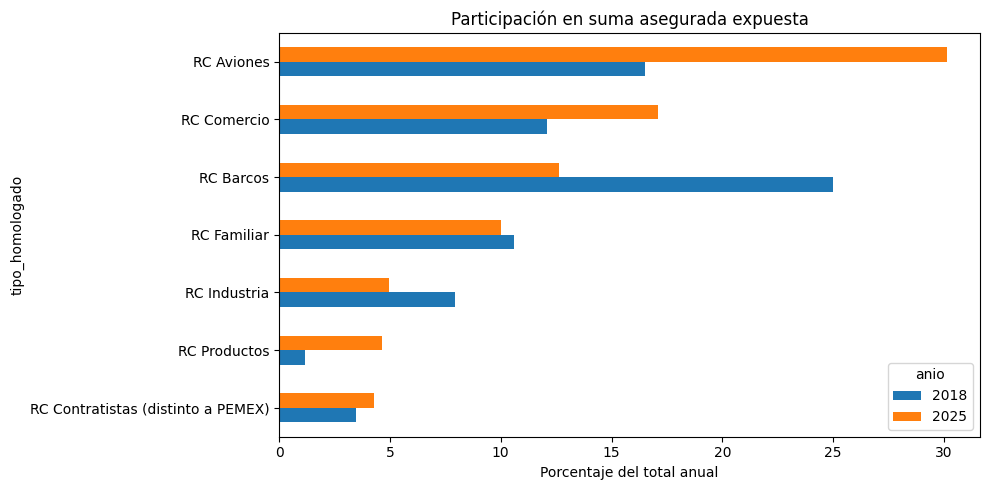

In [ ]:
exposicion = df_final.pivot(index="tipo_homologado", columns="anio",
                           values="suma_asegurada_expuesta")[[2018, 2025]]
participacion_suma = 100 * exposicion / exposicion.sum()

resumen_suma = participacion_suma.rename(
    columns={2018: "participacion_2018_pct", 2025: "participacion_2025_pct"}
)
resumen_suma["cambio_pp"] = (
    resumen_suma["participacion_2025_pct"] - resumen_suma["participacion_2018_pct"]
)
display(resumen_suma.sort_values("participacion_2025_pct", ascending=False).head(5).round(2))
resumen_suma.to_csv(OUT / "participacion_suma.csv")

vista = participacion_suma.dropna().sort_values(2025).tail(7)
ax = vista.plot.barh(figsize=(10, 5), title="Participación en suma asegurada expuesta")
ax.set_xlabel("Porcentaje del total anual")
plt.tight_layout()
plt.savefig(FIG / "03_participacion_suma.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación.**

RC Aviones aumentó su participación de 16.5 % a 30.1 %, mientras RC Barcos disminuyó de 25.0 % a 12.6 %. La gráfica compara los límites expuestos reportados para los tipos presentes en ambos años. No mide directamente el riesgo de cada segmento ni el monto asegurado único.

**4.5 Participación en primas y siniestros en 2025**

,primas_pct,siniestros_pct,diferencia_pp
tipo_homologado,,,
RC Industria,12.69,50.70,38.01
RC Comercio,37.15,18.54,-18.62
RC Familiar,4.36,5.71,1.35
RC Riesgos Profesionales,11.88,5.10,-6.77
RC Contaminacion,3.58,3.61,0.02
RC Aviones,4.46,2.81,-1.64
RC Riesgos Gubernamentales,5.56,0.18,-5.39


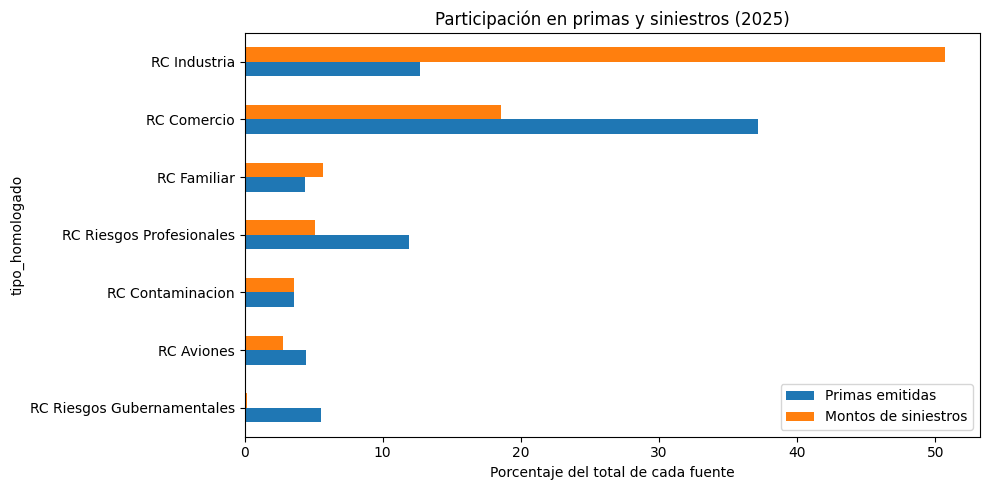

In [ ]:
comparacion = df_final.loc[
    df_final["anio"] == 2025,
    ["tipo_homologado", "prima_emitida", "monto_siniestro"]
].set_index("tipo_homologado")

comparacion["primas_pct"] = 100 * comparacion["prima_emitida"] / comparacion["prima_emitida"].sum()
comparacion["siniestros_pct"] = 100 * comparacion["monto_siniestro"] / comparacion["monto_siniestro"].sum()
comparacion["diferencia_pp"] = comparacion["siniestros_pct"] - comparacion["primas_pct"]

# Elegimos los cinco mayores de cada variable sin repetir tipos.
top_primas = comparacion["primas_pct"].nlargest(5).index
top_siniestros = comparacion["siniestros_pct"].nlargest(5).index
seleccion = top_primas.union(top_siniestros)
vista = comparacion.loc[seleccion, ["primas_pct", "siniestros_pct", "diferencia_pp"]]

display(vista.sort_values("siniestros_pct", ascending=False).round(2))
comparacion.to_csv(OUT / "participacion_primas_siniestros.csv")

# Mostramos únicamente los tipos con información de ambas variables.
vista = vista.dropna().sort_values("siniestros_pct")
ax = vista[["primas_pct", "siniestros_pct"]].plot.barh(
    figsize=(10, 5), title="Participación en primas y siniestros (2025)"
)
ax.set_xlabel("Porcentaje del total de cada fuente")
ax.legend(["Primas emitidas", "Montos de siniestros"])
plt.tight_layout()
plt.savefig(FIG / "04_primas_siniestros.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación.**

RC Comercio concentra aproximadamente 37.2 % de las primas y 18.5 % de los montos de siniestros. RC Industria representa 12.7 % de las primas y 50.7 % de los siniestros. La diferencia en puntos porcentuales describe la composición de los montos de cada fuente; no equivale a una tasa de siniestralidad, a rentabilidad ni a una medida de riesgo actuarial.

## 5. Interpretación y conclusiones

- Las primas emitidas y los montos de siniestros muestran una tendencia creciente entre 2018 y 2025 en los cálculos preliminares realizados. RC Comercio se consolidó como el principal segmento por participación en primas emitidas durante 2025, concentrando una proporción relevante del mercado analizado.
- RC Aviones concentró la mayor participación de suma asegurada expuesta en 2025 y aumentó su importancia relativa respecto a 2018. Esto sugiere cambios en la composición de la exposición entre los distintos tipos de seguros de Responsabilidad Civil.
- RC Industria concentró la mayor proporción de montos de siniestros en 2025, aunque no ocupó el primer lugar en primas emitidas. Este resultado muestra que los segmentos dominantes varían según la variable analizada y destaca la importancia de evaluar conjuntamente producción, exposición y siniestros.
- El análisis de frecuencias mostró una concentración importante de registros en determinados tipos de seguro, lo que confirma que la actividad del ramo no se distribuye de forma homogénea entre todos los segmentos analizados.
- La comparación entre media, mediana, cuartiles y percentiles permitió identificar distribuciones asimétricas y una concentración considerable de los montos en algunos tipos de seguro. Por esta razón, las medidas de posición complementan la interpretación de los promedios y aportan una visión más robusta de los datos.
- El análisis de correlaciones evidenció asociaciones positivas entre varias de las variables relacionadas con la actividad aseguradora, particularmente entre las distintas medidas de primas y las variables de exposición y siniestros. Sin embargo, estas asociaciones son descriptivas y no deben interpretarse como relaciones causales.
- Desde el punto de vista metodológico, homologar los tipos de seguro, seleccionar un periodo común de análisis, agrupar antes de integrar las bases y conservar los valores faltantes y negativos fueron decisiones fundamentales para evitar la fragmentación, duplicación o pérdida de información.

**Limitaciones.** Los montos son nominales si se confirma una unidad monetaria común; no se ha verificado la comparabilidad de `moneda`, ni se ha ajustado por inflación. Las sumas aseguradas pueden acumular distintas coberturas. No podemos afirmar causalidad, rentabilidad ni siniestralidad actuarial. Antes de entregar como cifras definitivas, corroborar las unidades en las notas técnicas; si no hay unidad común, rehacer primas y siniestros por categorías de moneda comparables.

**Reproducibilidad.** Ejecutar las celdas de principio a fin con los tres CSV originales en `data/raw/`. Los resultados se guardan en `data/processed/` y las figuras en `figures/`. Las dependencias utilizadas son `pandas`, `numpy`, `matplotlib` e `ipython`.

**Fuentes:** [Datos abiertos CNSF](https://www.cnsf.gob.mx/Transparencia/Paginas/DatosAbiertos.aspx) — archivos 33, 34 y 35 de Responsabilidad Civil; [descripción institucional de la información estadística](https://www.cnsf.gob.mx/EntidadesSupervisadas/InstitucionesSociedadesMutualistas/Paginas/ResponsabilidadCivil.aspx).